# Lab: MLP Backpropagation, initialization, and parameter updates

**BINF 6210/8210 - Machine Learning for Bioinformatics**
___

**Objective:**

- Implement a 2 → 3 → 1 MLP with tanh hidden units, sigmoid output, and binary cross-entropy (BCE).
- Use **mean** BCE, so the batch gradient includes `1 / batch_size`.
- The lecture derives MSE gradients; for sigmoid+BCE the output error simplifies to $\delta^{(out)}=\hat y-y$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
SEED = 42

In [3]:
def sigmoid(z): return 1/(1+np.exp(-np.clip(z,-500,500)))

def initialize(seed=42, mode='xavier'):
    rng = np.random.default_rng(seed)
    if mode=='zeros': W1=np.zeros((2,3)); W2=np.zeros((3,1))
    else:
        W1 = rng.normal(0,np.sqrt(2/(2+3)),(2,3))
        W2 = rng.normal(0,np.sqrt(2/(3+1)),(3,1))
    return [W1,np.zeros(3),W2,np.zeros(1)]

def forward(X, params):
    W1, b1, W2, b2 = params
    Z1 =X@W1 + b1;
    A1 = np.tanh(Z1)
    Z2 = A1@W2+b2;
    P = sigmoid(Z2)
    return P, (X, Z1, A1, Z2)

def loss(X, y, params):
    p, _ = forward(X, params)
    return -np.mean(y*np.log(np.clip(p,1e-12,1))+(1-y)*np.log(np.clip(1-p,1e-12,1)))

def gradients(X, y, params):
    W1, b1, W2, b2 = params
    p, (X, Z1, A1, Z2) = forward(X,params)
    m = len(X);
    delta2 = (p-y)/m
    dW2 = A1.T@delta2;
    db2 = delta2.sum(axis=0)
    delta1 = (delta2@W2.T)*(1-A1**2)
    dW1 = X.T@delta1;
    db1 = delta1.sum(axis=0)
    return [dW1,db1,dW2,db2]

In [4]:
X = np.array([[.3,-.8],[1.2,.4],[-.4,.9],[.8,1.1]])
y = np.array([[0.],[1.],[0.],[1.]])
params=initialize()
print('Initial BCE:',loss(X,y,params))
for label,g in zip(['dW1','db1','dW2','db2'],gradients(X,y,params)):
    print(label,g.shape)

Initial BCE: 0.6374521262164264
dW1 (2, 3)
db1 (3,)
dW2 (3, 1)
db2 (1,)


## 1. Verify backpropagation with finite differences
For each parameter $	heta$, compare analytical $\partial J/\partial	heta$ with $[J(	heta+\epsilon)-J(	heta-\epsilon)]/(2\epsilon)$. This is a diagnostic, not a practical training algorithm.

In [6]:
eps=1e-5
analytic = gradients(X, y, params)
for k in range(len(params)):
    numeric = np.zeros_like(params[k])
    for index in np.ndindex(params[k].shape):
        plus = [a.copy() for a in params]; minus=[a.copy() for a in params]
        plus[k][index] += eps; minus[k][index]-=eps
        numeric[index] = (loss(X,y,plus)-loss(X,y,minus))/(2*eps)
    print('parameter',k,'max absolute gradient error',np.max(np.abs(numeric-analytic[k])))
    assert np.allclose(numeric,analytic[k],atol=1e-6)

parameter 0 max absolute gradient error 7.014671395827454e-12
parameter 1 max absolute gradient error 9.566629714970187e-12
parameter 2 max absolute gradient error 1.1417464142095962e-11
parameter 3 max absolute gradient error 6.265821195228227e-13


**Exercise 1:** Derive `dW2 = A1.T @ delta2` and explain why the bias gradient sums over samples. What changes for MSE with a sigmoid output?

## 2. One parameter update and mini-batch averaging

In [7]:
alpha=.1
before=loss(X,y,params)
g=gradients(X,y,params)
updated=[a-alpha*d for a,d in zip(params,g)]
print('before',before,'after',loss(X,y,updated))
# Batch gradient equals size-weighted average of sample gradients
per_sample=[gradients(X[i:i+1],y[i:i+1],params) for i in range(len(X))]
for k in range(4):
    assert np.allclose(g[k],np.mean([s[k] for s in per_sample],axis=0))
print('Mean of individual sample gradients equals full-batch gradient.')

before 0.6374521262164264 after 0.6330127364083645
Mean of individual sample gradients equals full-batch gradient.


## 3. SGD, mini-batch, and full-batch training
Each epoch shuffles samples. The last incomplete batch is retained. Compare learning curves by **epoch** and note that update counts differ.

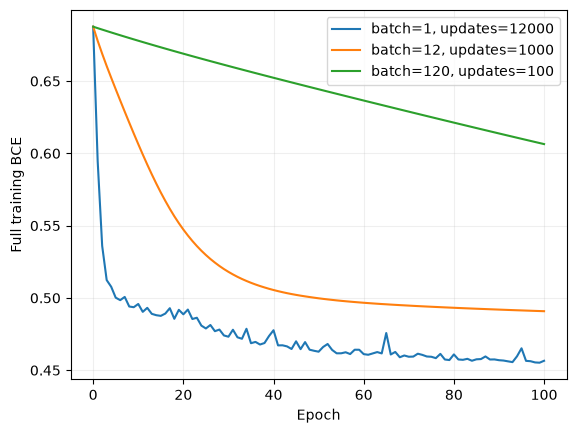

In [8]:
def train(X,y,batch_size,epochs=100,lr=.1,seed=42):
    rng=np.random.default_rng(seed); par=initialize(seed)
    history=[loss(X,y,par)]; updates=0
    for epoch in range(epochs):
        order=rng.permutation(len(X))
        for start in range(0,len(X),batch_size):
            idx=order[start:start+batch_size]
            g=gradients(X[idx],y[idx],par)
            par=[a-lr*d for a,d in zip(par,g)]
            updates+=1
        history.append(loss(X,y,par))
    return par,np.array(history),updates
rng=np.random.default_rng(SEED)
Xtrain=rng.normal(size=(120,2))
prob=sigmoid(-.5+1.3*Xtrain[:,0]-.8*Xtrain[:,1]+.8*Xtrain[:,0]*Xtrain[:,1])
ytrain=rng.binomial(1,prob).reshape(-1,1)
for b in [1,12,len(Xtrain)]:
    par,h,updates=train(Xtrain,ytrain,b,epochs=100,lr=.05)
    plt.plot(h,label=f'batch={b}, updates={updates}')
plt.xlabel('Epoch');plt.ylabel('Full training BCE');plt.legend();plt.grid(alpha=.2);plt.show()

**Exercise 2:** Compute updates per epoch for $m=120$ and $B=1,12,120$. Why does an equal epoch count not mean an equal number of updates? Repeat using a smaller learning rate.

## 4. Weight initialization: symmetry and variance

In [9]:
rng=np.random.default_rng(SEED)
Xwide=rng.normal(size=(2000,100))
for mode in ['zeros','small','xavier','he']:
    if mode=='zeros': W=np.zeros((100,80))
    elif mode=='small': W=rng.normal(0,.001,(100,80))
    elif mode=='xavier': W=rng.normal(0,np.sqrt(2/(100+80)),(100,80))
    else: W=rng.normal(0,np.sqrt(2/100),(100,80))
    Z=Xwide@W
    print(mode,'Var(Z)',round(Z.var(),4),'mean(ReLU(Z)^2)',round(np.mean(np.maximum(Z,0)**2),4))

zeros Var(Z) 0.0 mean(ReLU(Z)^2) 0.0
small Var(Z) 0.0001 mean(ReLU(Z)^2) 0.0
xavier Var(Z) 1.09 mean(ReLU(Z)^2) 0.5445
he Var(Z) 2.0261 mean(ReLU(Z)^2) 1.013


**Exercise 3:** Explain why zero initialization causes hidden-unit symmetry. Derive $\operatorname{Var}(z)pprox n_{in}\operatorname{Var}(w)\operatorname{Var}(x)$ under the lecture assumptions. Explain the factor of two in He initialization (the relevant quantity for ReLU is the second moment).

**Exit questions:** What is $\delta$? Why do we average gradients *before* a mini-batch update? How does batch size affect gradient variability?